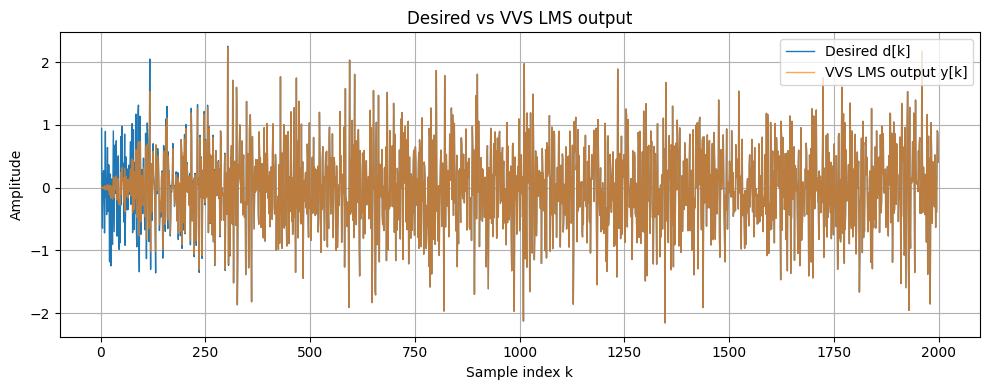

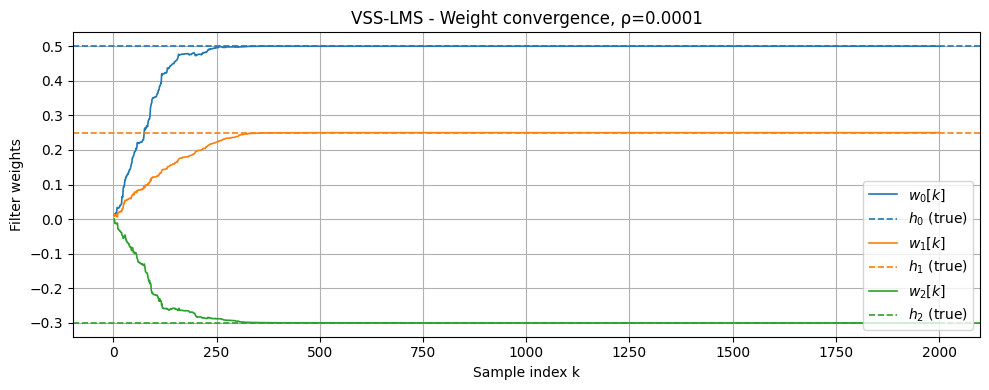

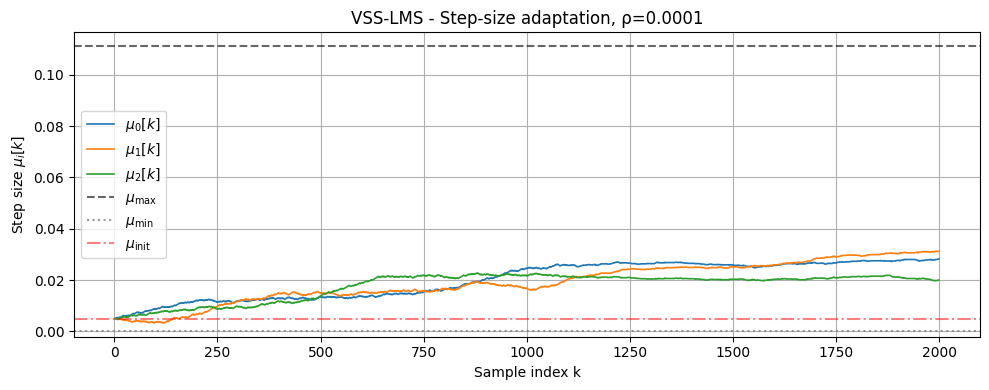

In [14]:
import numpy as np
import matplotlib.pyplot as plt

N = 2000 # samples
M = 3 # tabs
MU_init = 0.005 #inital value
MU_max = 0.1111
MU_min = 0.00005
rho = 0.0001


h = np.array([0.5,0.25,-0.3])
seed = 11
noise_std = 1.0

rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)


d = np.convolve(x,h,mode="full")[:N]


results = {}
w = np.zeros(M)
y = np.zeros(N)
e = np.zeros(N)
g_i = np.zeros(M)
u_i = np.zeros(M)
mu = np.full(M, MU_init)
g_old = np.zeros(M)


w_history = np.zeros((N,M))
mu_history = np.zeros((N,M))


for k in range(M-1, N):
    x_vec = x[k-M+1:k+1][::-1]

    y[k] = np.dot(w,x_vec)

    e[k] = d[k] - y[k]

    #update tap weights and step size parameters (from slide #42)
    for i in range(M):

        g = e[k] * x[k-i] #gradient contribution

        #update individual step size
        if k > M - 1:
            mu[i] += rho * np.sign(g) * np.sign(g_old[i])

        #limit
        mu[i] = np.clip(mu[i], MU_min, MU_max)

        w[i] += 2* mu[i] * g

        g_old[i] = g

    w_history[k] = w
    mu_history[k] = mu


# Plot settings
samples = np.arange(M-1, N)

# --------------------------------------------------
# 1. Squared error
# --------------------------------------------------
plt.figure(figsize=(10, 4))

# plt.plot(samples, e[M-1:]**2,
#          linewidth=0.8, label=r"$e^2[k]$")

# plt.xlabel("Sample index k")
# plt.ylabel(r"Squared error $e^2[k]$")
# plt.title("VSS-LMS - Squared error")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.savefig("vss_squared_error.pdf", bbox_inches="tight")
# plt.show()

plt.plot(samples, d[M-1:], label="Desired d[k]", linewidth=1)
plt.plot(samples, y[M-1:], label="VVS LMS output y[k]", linewidth=1, alpha=0.7)
plt.title("Desired vs VVS LMS output")
plt.ylabel("Amplitude")
plt.xlabel("Sample index k")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. Weight convergence
# --------------------------------------------------
plt.figure(figsize=(10, 4))

for i in range(M):
    line, = plt.plot(samples, w_history[M-1:, i],
                     linewidth=1.2,
                     label=rf"$w_{i}[k]$")

    # True coefficient, matching color
    plt.axhline(h[i],
                color=line.get_color(),
                linestyle="--",
                linewidth=1.2,
                label=rf"$h_{i}$ (true)")

plt.xlabel("Sample index k")
plt.ylabel("Filter weights")
plt.title(f"VSS-LMS - Weight convergence, ρ={rho}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("vss_weights.pdf", bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 3. Step-size adaptation
# --------------------------------------------------
plt.figure(figsize=(10, 4))

for i in range(M):
    plt.plot(samples, mu_history[M-1:, i],
             linewidth=1.2,
             label=rf"$\mu_{i}[k]$")

plt.axhline(MU_max,
            color="black", linestyle="--",
            alpha=0.6, label=r"$\mu_{\max}$")

plt.axhline(MU_min,
            color="gray", linestyle=":",
            alpha=0.8, label=r"$\mu_{\min}$")

plt.axhline(MU_init,
            color="red", linestyle="-.",
            alpha=0.5, label=r"$\mu_{\mathrm{init}}$")

plt.xlabel("Sample index k")
plt.ylabel(r"Step size $\mu_i[k]$")
plt.title(f"VSS-LMS - Step-size adaptation, ρ={rho}")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("vss_step_size.pdf", bbox_inches="tight")
plt.show()





